# Proyecto Minería de Datos — Predicción del riesgo de diabetes
## Tercer corte · Actividad 1: revisión, optimización y serialización del modelo para su despliegue en Streamlit

**Asignatura:** Minería de Datos · Universidad de la Costa (CUC)

| Integrante | Código estudiantil |
|---|---|
| Jesús Alberto Vargas España | *jvargas72@cuc.edu.co* |
| Santiago Patiño Arzayus | *spatino2@cuc.edu.co* |
| Duván Andrés Arzuza Carrascal | *darzuza@cuc.edu.co* |

**Datos:** *Diabetes Health Indicators Dataset* (BRFSS 2015, CDC), versión balanceada 50/50 (`diabetes_binary_5050split_health_indicators_BRFSS2015.csv`, Kaggle).

### Qué cambió respecto al avance del segundo corte (evolución del proyecto)
1. **Notebook lineal y reproducible:** una sola limpieza, una sola partición y un solo bloque de modelado; ejecución de arriba hacia abajo.
2. **Eliminación real de duplicados en el código** (en el corte 2 solo se imprimía el `shape`).
3. **Preprocesamiento dentro de un `Pipeline`:** el escalado se ajusta solo con entrenamiento, también durante la validación cruzada (sin fuga de información). Antes solo se escalaba `bmi`.
4. **Validación cruzada estratificada (5 folds)** y comparación **antes vs. después** de la optimización.
5. **Selección del modelo y del umbral de decisión** con criterio clínico (sensibilidad), sin usar el conjunto de prueba.
6. **Todas las cifras de las conclusiones se generan desde el código**, para que notebook e informe sean coherentes.
7. **Pipeline completo serializado con `joblib`**, verificado con una prueba de ida y vuelta.

In [ ]:
import os, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, joblib
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
CARPETA_ARTEFACTOS = "artefactos"
os.makedirs(CARPETA_ARTEFACTOS, exist_ok=True)

print("Python      :", platform.python_version())
for lib in (np, pd, sklearn, joblib):
    print(f"{lib.__name__:<12}:", lib.__version__)

Python      : 3.12.3
numpy       : 2.4.4
pandas      : 3.0.2
sklearn     : 1.8.0
joblib      : 1.5.3


## 1. Carga y limpieza reproducible (CRISP-DM · Preparación de datos)
Se carga el archivo original, se estandarizan los nombres de columnas, se verifican nulos y se **eliminan** los duplicados exactos.
La limpieza queda en **una sola celda** para que "Reiniciar y ejecutar todo" produzca siempre las mismas cifras.

In [ ]:
NOMBRE_CSV = "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

if not os.path.exists(NOMBRE_CSV):               # Google Colab: pedir el archivo al usuario
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Coloca '{NOMBRE_CSV}' en la misma carpeta del notebook.")

df_raw = pd.read_csv(NOMBRE_CSV)

df = df_raw.copy()
df.columns = df.columns.str.strip().str.lower()

n_filas_ini, n_cols = df.shape
n_nulos = int(df.isna().sum().sum())
n_dup = int(df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)      # <- eliminación REAL de duplicados
df["diabetes_binary"] = df["diabetes_binary"].astype(int)

resumen_limpieza = pd.DataFrame({
    "Concepto": ["Filas iniciales", "Columnas", "Valores nulos", "Filas duplicadas exactas", "Filas después de limpiar"],
    "Valor": [n_filas_ini, n_cols, n_nulos, n_dup, len(df)],
})
display(resumen_limpieza)

conteo = df["diabetes_binary"].value_counts().sort_index()
print("\nDistribución del objetivo tras limpiar:")
print(conteo.to_string(), "\n", (conteo / len(df)).round(4).to_string())

,Concepto,Valor
0,Filas iniciales,70692
1,Columnas,22
2,Valores nulos,0
3,Filas duplicadas exactas,1635
4,Filas después de limpiar,69057



Distribución del objetivo tras limpiar:
diabetes_binary
0    33960
1    35097 
 diabetes_binary
0    0.4918
1    0.5082


In [ ]:
display(Markdown(f"""
**Interpretación.** El archivo tiene **{n_filas_ini:,}** filas y **{n_cols}** columnas, **{n_nulos}** valores nulos y **{n_dup:,}** filas duplicadas exactas.
Se eliminaron los duplicados para que una misma observación no aparezca en entrenamiento y prueba (lo que inflaría las métricas),
quedando **{len(df):,}** registros. Tras la limpieza las clases son **{conteo[0]:,}** (sin diabetes) y **{conteo[1]:,}** (diabetes/prediabetes):
{conteo[1]/len(df):.2%} de positivos, un balance suficiente para no aplicar remuestreo sintético.
"""))


**Interpretación.** El archivo tiene **70,692** filas y **22** columnas, **0** valores nulos y **1,635** filas duplicadas exactas.
Se eliminaron los duplicados para que una misma observación no aparezca en entrenamiento y prueba (lo que inflaría las métricas),
quedando **69,057** registros. Tras la limpieza las clases son **33,960** (sin diabetes) y **35,097** (diabetes/prediabetes):
50.82% de positivos, un balance suficiente para no aplicar remuestreo sintético.


## 2. EDA mínimo orientado a decisiones de modelado
La guía pide **no repetir todo el EDA**. Solo se conservan los análisis que justifican decisiones del modelo (variables más asociadas, outliers de `bmi`, escala de las variables)
y los **datos verificados** que se mostrarán en la aplicación.

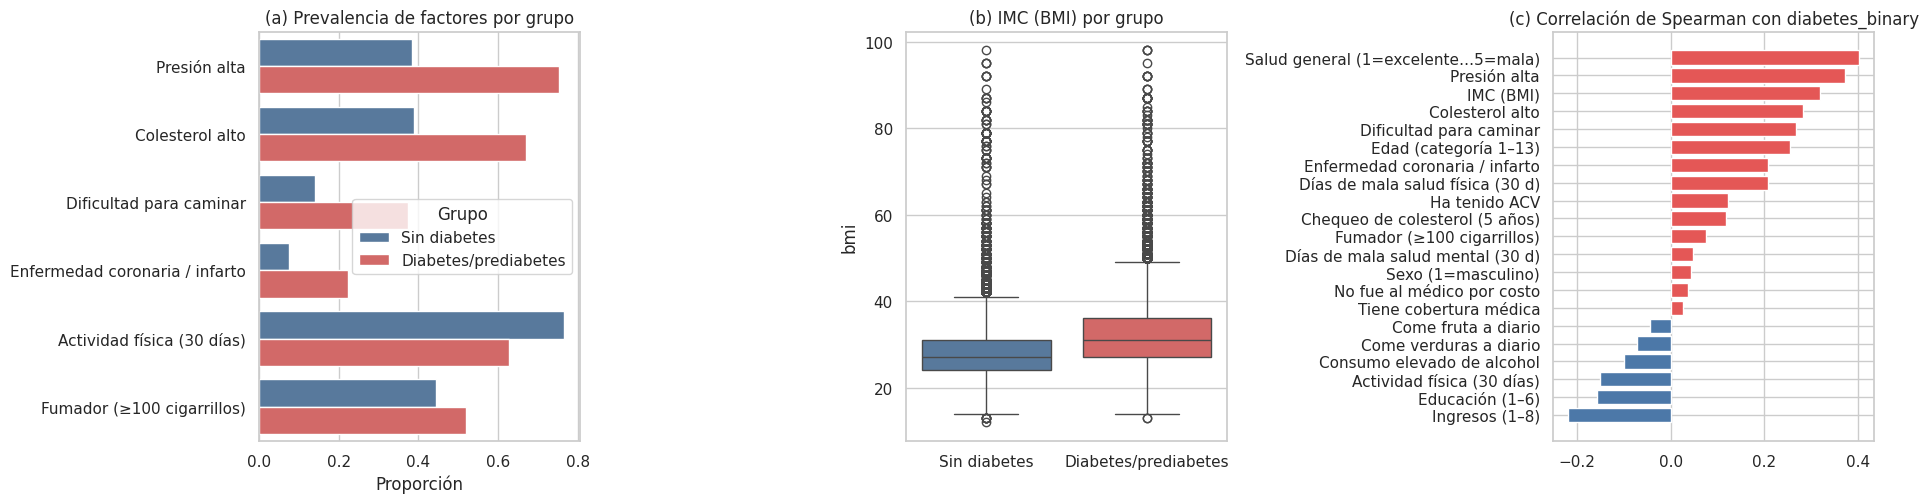

,count,mean,std,min,25%,50%,75%,max
diabetes_binary,,,,,,,,
0,33960.0,27.88,6.26,12.0,24.0,27.0,31.0,98.0
1,35097.0,31.96,7.38,13.0,27.0,31.0,36.0,98.0


Registros con BMI > 60: 260 (0.377%); BMI máximo: 98


In [ ]:
ETIQUETAS = {
    "highbp": "Presión alta", "highchol": "Colesterol alto", "cholcheck": "Chequeo de colesterol (5 años)",
    "bmi": "IMC (BMI)", "smoker": "Fumador (≥100 cigarrillos)", "stroke": "Ha tenido ACV",
    "heartdiseaseorattack": "Enfermedad coronaria / infarto", "physactivity": "Actividad física (30 días)",
    "fruits": "Come fruta a diario", "veggies": "Come verduras a diario", "hvyalcoholconsump": "Consumo elevado de alcohol",
    "anyhealthcare": "Tiene cobertura médica", "nodocbccost": "No fue al médico por costo",
    "genhlth": "Salud general (1=excelente…5=mala)", "menthlth": "Días de mala salud mental (30 d)",
    "physhlth": "Días de mala salud física (30 d)", "diffwalk": "Dificultad para caminar",
    "sex": "Sexo (1=masculino)", "age": "Edad (categoría 1–13)", "education": "Educación (1–6)", "income": "Ingresos (1–8)",
}
binarias_eda = ["highbp", "highchol", "diffwalk", "heartdiseaseorattack", "physactivity", "smoker"]

prev = df.groupby("diabetes_binary")[binarias_eda].mean().T
prev.columns = ["Sin diabetes", "Diabetes/prediabetes"]
corr_target = df.corr(method="spearman")["diabetes_binary"].drop("diabetes_binary").sort_values()

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
p = prev.rename(index=ETIQUETAS).reset_index().melt(id_vars="index", var_name="Grupo", value_name="Proporción")
sns.barplot(data=p, y="index", x="Proporción", hue="Grupo", ax=ax[0], palette=["#4C78A8", "#E45756"])
ax[0].set_title("(a) Prevalencia de factores por grupo"); ax[0].set_ylabel("")

sns.boxplot(data=df, x="diabetes_binary", y="bmi", ax=ax[1], palette=["#4C78A8", "#E45756"])
ax[1].set_xticklabels(["Sin diabetes", "Diabetes/prediabetes"]); ax[1].set_xlabel("")
ax[1].set_title("(b) IMC (BMI) por grupo")

ax[2].barh([ETIQUETAS[c] for c in corr_target.index], corr_target.values,
           color=["#E45756" if v > 0 else "#4C78A8" for v in corr_target.values])
ax[2].set_title("(c) Correlación de Spearman con diabetes_binary")
plt.tight_layout(); plt.show()

bmi_stats = df.groupby("diabetes_binary")["bmi"].describe()
display(bmi_stats.round(2))
n_bmi_ext = int((df["bmi"] > 60).sum())
print(f"Registros con BMI > 60: {n_bmi_ext} ({n_bmi_ext/len(df):.3%}); BMI máximo: {df['bmi'].max():.0f}")

In [ ]:
top_pos = corr_target.sort_values(ascending=False).head(4)
top_neg = corr_target.sort_values().head(2)
display(Markdown(f"""
**Interpretación.**
- Entre diabéticos/prediabéticos, **{prev.loc['highbp','Diabetes/prediabetes']:.1%}** tiene presión alta frente a **{prev.loc['highbp','Sin diabetes']:.1%}** del otro grupo;
  para colesterol alto: **{prev.loc['highchol','Diabetes/prediabetes']:.1%}** vs **{prev.loc['highchol','Sin diabetes']:.1%}**.
- Las correlaciones de Spearman más altas con el objetivo son: {", ".join(f"`{k}` ({v:+.2f})" for k, v in top_pos.items())}.
  Las más negativas: {", ".join(f"`{k}` ({v:+.2f})" for k, v in top_neg.items())}.
  Son asociaciones **moderadas** (ninguna supera |0.5|): ninguna variable por sí sola separa las clases, por eso se necesita un modelo multivariable.
- La mediana de `bmi` es **{bmi_stats.loc[0,'50%']:.0f}** (sin diabetes) y **{bmi_stats.loc[1,'50%']:.0f}** (con diabetes).
  Solo {n_bmi_ext} registros superan BMI 60; **se conservan** porque son valores biológicamente posibles (obesidad mórbida) y los modelos de árboles y la regresión regularizada toleran bien estos extremos.
- Decisión de modelado: `age`, `genhlth`, `income`, `education`, `menthlth`, `physhlth` y `bmi` tienen escalas distintas (1–13, 1–5, 1–8, 0–30, 12–98) → se estandarizan **todas** dentro del pipeline (en el corte 2 solo se escalaba `bmi`).
"""))


**Interpretación.**
- Entre diabéticos/prediabéticos, **75.2%** tiene presión alta frente a **38.4%** del otro grupo;
  para colesterol alto: **66.9%** vs **38.9%**.
- Las correlaciones de Spearman más altas con el objetivo son: `genhlth` (+0.40), `highbp` (+0.37), `bmi` (+0.32), `highchol` (+0.28).
  Las más negativas: `income` (-0.22), `education` (-0.16).
  Son asociaciones **moderadas** (ninguna supera |0.5|): ninguna variable por sí sola separa las clases, por eso se necesita un modelo multivariable.
- La mediana de `bmi` es **27** (sin diabetes) y **31** (con diabetes).
  Solo 260 registros superan BMI 60; **se conservan** porque son valores biológicamente posibles (obesidad mórbida) y los modelos de árboles y la regresión regularizada toleran bien estos extremos.
- Decisión de modelado: `age`, `genhlth`, `income`, `education`, `menthlth`, `physhlth` y `bmi` tienen escalas distintas (1–13, 1–5, 1–8, 0–30, 12–98) → se estandarizan **todas** dentro del pipeline (en el corte 2 solo se escalaba `bmi`).


In [ ]:
# Datos agregados y una muestra pequeña para los gráficos interactivos de la app (no contienen datos personales: son respuestas de encuesta anonimizadas)
eda_stats = {
    "n_registros": int(len(df)),
    "clases": {"sin_diabetes": int(conteo[0]), "con_diabetes": int(conteo[1])},
    "prevalencia": {ETIQUETAS[k]: {"sin_diabetes": float(prev.loc[k, "Sin diabetes"]),
                                   "con_diabetes": float(prev.loc[k, "Diabetes/prediabetes"])} for k in prev.index},
    "correlacion_spearman": {ETIQUETAS[k]: float(v) for k, v in corr_target.items()},
    "bmi_mediana": {"sin_diabetes": float(bmi_stats.loc[0, "50%"]), "con_diabetes": float(bmi_stats.loc[1, "50%"])},
}
with open(f"{CARPETA_ARTEFACTOS}/eda_stats.json", "w", encoding="utf-8") as f:
    json.dump(eda_stats, f, ensure_ascii=False, indent=2)
df.sample(6000, random_state=RANDOM_STATE)[["diabetes_binary", "bmi", "age", "genhlth"]].to_csv(f"{CARPETA_ARTEFACTOS}/eda_muestra.csv", index=False)
print("Guardados: eda_stats.json y eda_muestra.csv")

Guardados: eda_stats.json y eda_muestra.csv


## 3. Partición entrenamiento / prueba
Una **única** partición 80/20, estratificada por `diabetes_binary` y con semilla fija. El conjunto de prueba **no se usa** para elegir hiperparámetros ni el umbral:
esas decisiones se toman solo con validación cruzada sobre entrenamiento.

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = df.drop(columns="diabetes_binary")
y = df["diabetes_binary"]
FEATURES = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}")
print("Proporción de positivos  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: (55245, 21) | Prueba: (13812, 21)
Proporción de positivos  train: 0.5082 | test: 0.5083


## 4. Revisión del modelo del corte 2 — resultados **ANTES**
Se reproducen los cinco clasificadores del avance anterior **con la misma configuración** (solo `bmi` escalado, `GradientBoostingClassifier` con parámetros por defecto) y se agrega **validación cruzada estratificada de 5 folds sobre entrenamiento**, que faltaba.
Se reporta la sensibilidad (**Recall de la clase 1**, no el *macro-recall*), la especificidad y los falsos negativos.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

def metricas(y_true, proba, umbral=0.5):
    pred = (np.asarray(proba) >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred), "Especificidad": tn / (tn + fp),
            "F1": f1_score(y_true, pred), "F2": fbeta_score(y_true, pred, beta=2),
            "ROC_AUC": roc_auc_score(y_true, proba), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

def evaluar(nombre, pipe, etapa):
    """Validación cruzada (train) + evaluación en prueba con umbral 0.5."""
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=1)
    pipe.fit(X_train, y_train)
    pt = pipe.predict_proba(X_test)[:, 1]
    fila = {"Etapa": etapa, "Modelo": nombre}
    fila.update({f"CV_{k}": r[f"test_{k}"].mean() for k in SCORING})
    fila.update({f"CVstd_{k}": r[f"test_{k}"].std() for k in ("recall", "roc_auc")})
    fila["AUC_train"] = roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1])
    fila.update({f"Test_{k}": v for k, v in metricas(y_test, pt).items()})
    return fila, pipe

def preproc_antes():   # corte 2: solo bmi escalado
    return ColumnTransformer([("bmi", StandardScaler(), ["bmi"])], remainder="passthrough")

def modelos_corte2():
    return {
        "Regresión Logística": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "Árbol de Decisión": DecisionTreeClassifier(max_depth=7, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=15),
    }

filas_antes = []
for nombre, m in modelos_corte2().items():
    fila, _ = evaluar(nombre, Pipeline([("prep", preproc_antes()), ("clf", m)]), "ANTES")
    filas_antes.append(fila)
    print("listo:", nombre)

COLS_VISTA = ["Modelo", "CV_recall", "CVstd_recall", "CV_roc_auc", "CV_f1", "Test_Accuracy", "Test_Recall", "Test_Especificidad", "Test_ROC_AUC", "Test_FN", "AUC_train"]
tabla_antes = pd.DataFrame(filas_antes)
display(tabla_antes[COLS_VISTA].sort_values("CV_recall", ascending=False).round(4).reset_index(drop=True))

listo: Regresión Logística


listo: Árbol de Decisión


listo: Random Forest


listo: Gradient Boosting


listo: KNN


,Modelo,CV_recall,CVstd_recall,CV_roc_auc,CV_f1,Test_Accuracy,Test_Recall,Test_Especificidad,Test_ROC_AUC,Test_FN,AUC_train
0,Random Forest,0.7962,0.0064,0.8229,0.7616,0.7472,0.7997,0.6929,0.8195,1406,0.8790
1,Gradient Boosting,0.7953,0.0056,0.8259,0.7634,0.7500,0.7990,0.6994,0.8237,1411,0.8302
2,Árbol de Decisión,0.7820,0.0151,0.8087,0.7511,0.7377,0.7829,0.6910,0.8081,1524,0.8195
3,KNN,0.7726,0.0072,0.7861,0.7374,0.7205,0.7718,0.6674,0.7869,1602,0.8377
4,Regresión Logística,0.7710,0.0063,0.8200,0.7542,0.7447,0.7728,0.7157,0.8174,1595,0.8203


## 5. Lista de verificación de calidad del modelado (ficha técnica)
Se revisan los puntos que pide la guía, aunque la métrica principal supera el 70 %: fuga de información, desbalance, colinealidad, sobreajuste e hiperparámetros.

In [ ]:
# Colinealidad entre predictores
corr_pred = X.corr(method="spearman").abs()
pares = (corr_pred.where(np.triu(np.ones(corr_pred.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False).head(4))

# Vectores de características de prueba que también aparecen en entrenamiento (variables de baja cardinalidad)
solap = X_test.merge(X_train.drop_duplicates(), how="inner").shape[0]

gap = tabla_antes.set_index("Modelo")[["AUC_train", "Test_ROC_AUC"]].assign(Brecha=lambda d: d.AUC_train - d.Test_ROC_AUC)

display(Markdown(f"""
| Punto de la ficha | Verificación | Resultado |
|---|---|---|
| Tratamiento de datos | nulos y duplicados | {n_nulos} nulos; {n_dup:,} duplicados eliminados |
| Separación train/test | estratificada, semilla {RANDOM_STATE}, prueba sin uso en decisiones | {len(X_train):,} / {len(X_test):,} |
| Fuga de información | el escalado ahora vive dentro del `Pipeline` (se reajusta en cada fold) | sin fuga por preprocesamiento |
| Desbalance | proporción de positivos | {y.mean():.2%} (balanceado) |
| Colinealidad | pares de predictores con mayor correlación absoluta de Spearman | {"; ".join(f"{a}–{b}: {v:.2f}" for (a, b), v in pares.items())} |
| Sobreajuste | mayor brecha AUC train − test entre modelos ANTES | {gap.Brecha.idxmax()} ({gap.Brecha.max():.3f}) |
| Hiperparámetros | los del corte 2 eran fijos y sin justificar | se optimizan por validación cruzada (sección 6) |
| Variables de baja cardinalidad | filas de prueba cuyo vector de variables aparece también en entrenamiento | {solap:,} ({solap/len(X_test):.1%}); no es fuga (la etiqueta puede diferir), pero limita lo que el modelo puede separar |
"""))


| Punto de la ficha | Verificación | Resultado |
|---|---|---|
| Tratamiento de datos | nulos y duplicados | 0 nulos; 1,635 duplicados eliminados |
| Separación train/test | estratificada, semilla 42, prueba sin uso en decisiones | 55,245 / 13,812 |
| Fuga de información | el escalado ahora vive dentro del `Pipeline` (se reajusta en cada fold) | sin fuga por preprocesamiento |
| Desbalance | proporción de positivos | 50.82% (balanceado) |
| Colinealidad | pares de predictores con mayor correlación absoluta de Spearman | genhlth–physhlth: 0.52; genhlth–diffwalk: 0.46; physhlth–diffwalk: 0.46; education–income: 0.45 |
| Sobreajuste | mayor brecha AUC train − test entre modelos ANTES | Random Forest (0.059) |
| Hiperparámetros | los del corte 2 eran fijos y sin justificar | se optimizan por validación cruzada (sección 6) |
| Variables de baja cardinalidad | filas de prueba cuyo vector de variables aparece también en entrenamiento | 128 (0.9%); no es fuga (la etiqueta puede diferir), pero limita lo que el modelo puede separar |


## 6. Optimización — resultados **DESPUÉS**
Cambios aplicados y por qué:
1. **Escalado de todas las variables numéricas/ordinales dentro del `Pipeline`** (mejora a la regresión logística y KNN; no altera a los árboles).
2. **Búsqueda aleatoria de hiperparámetros** (`RandomizedSearchCV`, 3 folds, sobre entrenamiento) para `HistGradientBoostingClassifier`, con parada temprana para controlar el sobreajuste.
   Se optimiza **ROC-AUC** y no el Recall: maximizar Recall con umbral fijo 0.5 es una meta degenerada (basta con predecir más positivos). Primero se mejora la capacidad de **ordenar** pacientes por riesgo y después se fija el **umbral** explícitamente (sección 7).
3. Comparación con el mismo esquema de validación cruzada que en la etapa ANTES.

In [ ]:
NUMERICAS = ["bmi", "age", "genhlth", "menthlth", "physhlth", "education", "income"]
BINARIAS = [c for c in FEATURES if c not in NUMERICAS]

def preproc_despues():
    return ColumnTransformer([("num", StandardScaler(), NUMERICAS)], remainder="passthrough")

filas_despues, pipes = [], {}
for nombre, m in modelos_corte2().items():
    fila, p = evaluar(nombre, Pipeline([("prep", preproc_despues()), ("clf", m)]), "DESPUÉS (escalado completo)")
    filas_despues.append(fila); pipes[nombre] = p
    print("listo:", nombre)

listo: Regresión Logística


listo: Árbol de Decisión


listo: Random Forest


listo: Gradient Boosting


listo: KNN


In [ ]:
hgb = Pipeline([("prep", preproc_despues()),
                ("clf", HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.1,
                                                       n_iter_no_change=15, max_iter=500, random_state=RANDOM_STATE))])
espacio = {
    "clf__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "clf__max_leaf_nodes": [8, 15, 31, 63],
    "clf__min_samples_leaf": [20, 50, 100, 200],
    "clf__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    "clf__max_depth": [None, 4, 6],
}
busqueda = RandomizedSearchCV(hgb, espacio, n_iter=12, scoring="roc_auc", cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                              random_state=RANDOM_STATE, n_jobs=1, refit=True)
busqueda.fit(X_train, y_train)
mejores_params = {k.replace("clf__", ""): v for k, v in busqueda.best_params_.items()}
print("Mejores hiperparámetros:", mejores_params)
print("ROC-AUC medio (3 folds) del mejor:", round(busqueda.best_score_, 4))

NOMBRE_FINAL = "HistGradientBoosting (optimizado)"
fila_hgb, pipe_final = evaluar(NOMBRE_FINAL, busqueda.best_estimator_, "DESPUÉS (optimizado)")
filas_despues.append(fila_hgb)
tabla_despues = pd.DataFrame(filas_despues)
display(tabla_despues[COLS_VISTA].sort_values("CV_roc_auc", ascending=False).round(4).reset_index(drop=True))

Mejores hiperparámetros: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_depth': 4, 'learning_rate': 0.03, 'l2_regularization': 0.1}
ROC-AUC medio (3 folds) del mejor: 0.8257


,Modelo,CV_recall,CVstd_recall,CV_roc_auc,CV_f1,Test_Accuracy,Test_Recall,Test_Especificidad,Test_ROC_AUC,Test_FN,AUC_train
0,HistGradientBoosting (optimizado),0.7974,0.0057,0.8259,0.7634,0.7483,0.7997,0.6951,0.8239,1406,0.8344
1,Gradient Boosting,0.7953,0.0056,0.8259,0.7634,0.7500,0.7990,0.6994,0.8237,1411,0.8302
2,Random Forest,0.7979,0.0077,0.8231,0.7627,0.7465,0.7997,0.6914,0.8200,1406,0.8792
3,Regresión Logística,0.7710,0.0063,0.8200,0.7542,0.7449,0.7732,0.7157,0.8174,1592,0.8203
4,Árbol de Decisión,0.7820,0.0151,0.8086,0.7511,0.7378,0.7829,0.6911,0.8081,1524,0.8195
5,KNN,0.7789,0.0092,0.8001,0.7453,0.7317,0.7856,0.6759,0.8011,1505,0.8473


In [ ]:
# Comparación antes vs. después, modelo por modelo (validación cruzada, 5 folds)
comp = tabla_antes.set_index("Modelo")[["CV_recall", "CV_roc_auc", "Test_Recall", "Test_FN"]].join(
    tabla_despues.set_index("Modelo")[["CV_recall", "CV_roc_auc", "Test_Recall", "Test_FN"]],
    lsuffix="_antes", rsuffix="_despues", how="outer")
comp["Δ CV_roc_auc"] = comp["CV_roc_auc_despues"] - comp["CV_roc_auc_antes"]
comp["Δ CV_recall"] = comp["CV_recall_despues"] - comp["CV_recall_antes"]
display(comp.round(4))

mejor_cv = tabla_despues.sort_values("CV_roc_auc", ascending=False).iloc[0]
gb_antes = tabla_antes.set_index("Modelo").loc["Gradient Boosting"]
mejora = mejor_cv['CV_roc_auc'] - gb_antes['CV_roc_auc']
fila_final = tabla_despues.set_index("Modelo").loc[NOMBRE_FINAL]
rf_gap = tabla_despues.set_index("Modelo").loc["Random Forest", "AUC_train"] - tabla_despues.set_index("Modelo").loc["Random Forest", "Test_ROC_AUC"]
frase_mejora = ("la optimización de hiperparámetros **no mejora de forma apreciable** el ordenamiento de riesgo"
                if abs(mejora) < 0.005 else "una mejora apreciable del ordenamiento de riesgo")
display(Markdown(f"""
**Interpretación.**
- Los árboles y ensambles son invariantes al escalado (Gradient Boosting: Δ AUC-CV = {comp.loc['Gradient Boosting','Δ CV_roc_auc']:+.4f}); la regresión logística cambia {comp.loc['Regresión Logística','Δ CV_roc_auc']:+.4f}.
  **KNN**, que depende de distancias, es el que más se beneficia de escalar todas las variables (Δ AUC-CV = {comp.loc['KNN','Δ CV_roc_auc']:+.4f}).
- El mejor ROC-AUC en validación cruzada es **{mejor_cv['Modelo']}** ({mejor_cv['CV_roc_auc']:.4f} ± {mejor_cv['CVstd_roc_auc']:.4f}) frente a {gb_antes['CV_roc_auc']:.4f} del Gradient Boosting del corte 2:
  diferencia de **{mejora:+.4f}**, es decir, {frase_mejora}. El techo de rendimiento lo marca la información disponible en 21 variables autorreportadas más que el algoritmo.
  Se conserva el modelo optimizado porque iguala al mejor, es más regular (árboles poco profundos y parada temprana) y ocupa mucho menos espacio, no porque sea claramente superior.
- Brecha de sobreajuste del modelo final (AUC entrenamiento − AUC prueba): **{fila_final['AUC_train']-fila_final['Test_ROC_AUC']:.3f}**, frente a {rf_gap:.3f} del Random Forest.
- La desviación estándar entre folds del Recall es {mejor_cv['CVstd_recall']:.4f}: la sensibilidad es **estable**, y las diferencias entre modelos de ese orden no son concluyentes
  (en el corte 2, Gradient Boosting y Random Forest diferían en ~0.002 de recall y se declaró un ganador sin validación cruzada).
- **La mejora real de sensibilidad no proviene del algoritmo sino de la decisión del umbral** (sección 7).
"""))

,CV_recall_antes,CV_roc_auc_antes,Test_Recall_antes,Test_FN_antes,CV_recall_despues,CV_roc_auc_despues,Test_Recall_despues,Test_FN_despues,Δ CV_roc_auc,Δ CV_recall
Modelo,,,,,,,,,,
Gradient Boosting,0.7953,0.8259,0.7990,1411.0,0.7953,0.8259,0.7990,1411,-0.0000,0.0000
HistGradientBoosting (optimizado),NaN,NaN,NaN,NaN,0.7974,0.8259,0.7997,1406,NaN,NaN
KNN,0.7726,0.7861,0.7718,1602.0,0.7789,0.8001,0.7856,1505,0.0140,0.0063
Random Forest,0.7962,0.8229,0.7997,1406.0,0.7979,0.8231,0.7997,1406,0.0002,0.0017
Regresión Logística,0.7710,0.8200,0.7728,1595.0,0.7710,0.8200,0.7732,1592,0.0000,0.0000
Árbol de Decisión,0.7820,0.8087,0.7829,1524.0,0.7820,0.8086,0.7829,1524,-0.0000,-0.0000



**Interpretación.**
- Los árboles y ensambles son invariantes al escalado (Gradient Boosting: Δ AUC-CV = -0.0000); la regresión logística cambia +0.0000.
  **KNN**, que depende de distancias, es el que más se beneficia de escalar todas las variables (Δ AUC-CV = +0.0140).
- El mejor ROC-AUC en validación cruzada es **HistGradientBoosting (optimizado)** (0.8259 ± 0.0042) frente a 0.8259 del Gradient Boosting del corte 2:
  diferencia de **+0.0000**, es decir, la optimización de hiperparámetros **no mejora de forma apreciable** el ordenamiento de riesgo. El techo de rendimiento lo marca la información disponible en 21 variables autorreportadas más que el algoritmo.
  Se conserva el modelo optimizado porque iguala al mejor, es más regular (árboles poco profundos y parada temprana) y ocupa mucho menos espacio, no porque sea claramente superior.
- Brecha de sobreajuste del modelo final (AUC entrenamiento − AUC prueba): **0.010**, frente a 0.059 del Random Forest.
- La desviación estándar entre folds del Recall es 0.0057: la sensibilidad es **estable**, y las diferencias entre modelos de ese orden no son concluyentes
  (en el corte 2, Gradient Boosting y Random Forest diferían en ~0.002 de recall y se declaró un ganador sin validación cruzada).
- **La mejora real de sensibilidad no proviene del algoritmo sino de la decisión del umbral** (sección 7).


## 7. Selección del modelo y del umbral de decisión (criterio clínico)
**Por qué el Recall y no el Accuracy.** En tamizaje de diabetes los errores son asimétricos: un **falso negativo** (paciente con diabetes/prediabetes clasificado como sano) retrasa el diagnóstico y el control metabólico,
mientras que un **falso positivo** implica, en el peor caso, una prueba de glucosa de confirmación. Por eso se prioriza la **sensibilidad** (Recall de la clase 1 = TP / (TP + FN)) y se vigila la **especificidad** para no saturar de falsos positivos.
El Accuracy mezcla ambos errores con el mismo peso y oculta esta asimetría.

**Umbral.** El 0.5 por defecto no es sagrado. Se elige con las **predicciones fuera de muestra de la validación cruzada** (solo entrenamiento):
el **umbral más alto** (máxima especificidad) que logra una sensibilidad de al menos `RECALL_OBJETIVO`. El valor 0.85 es una decisión de diseño del equipo, modificable.

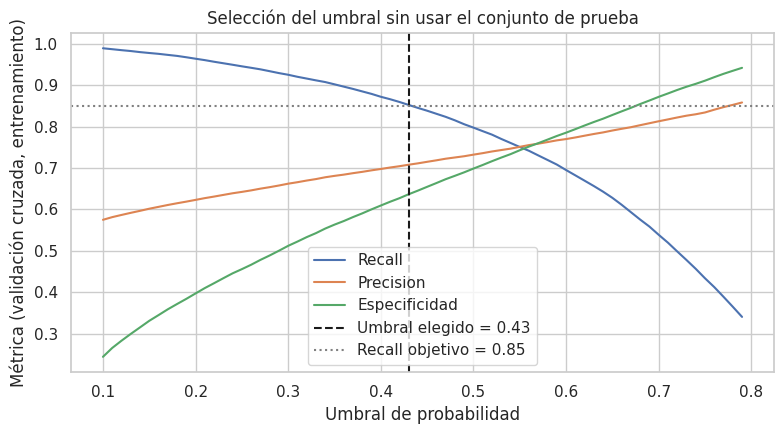

Umbral elegido: 0.43


In [ ]:
from sklearn.base import clone

RECALL_OBJETIVO = 0.85
oof = cross_val_predict(clone(pipe_final), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

grilla = np.round(np.arange(0.10, 0.80, 0.01), 2)
curva = pd.DataFrame({
    "umbral": grilla,
    "recall": [recall_score(y_train, oof >= t) for t in grilla],
    "precision": [precision_score(y_train, oof >= t) for t in grilla],
    "especificidad": [((oof < t) & (y_train == 0)).sum() / (y_train == 0).sum() for t in grilla],
})
cumplen = curva[curva.recall >= RECALL_OBJETIVO]
UMBRAL = float(cumplen.umbral.max()) if len(cumplen) else 0.5

plt.figure(figsize=(8, 4.5))
for c in ("recall", "precision", "especificidad"):
    plt.plot(curva.umbral, curva[c], label=c.capitalize())
plt.axvline(UMBRAL, color="k", ls="--", label=f"Umbral elegido = {UMBRAL:.2f}")
plt.axhline(RECALL_OBJETIVO, color="gray", ls=":", label=f"Recall objetivo = {RECALL_OBJETIVO}")
plt.xlabel("Umbral de probabilidad"); plt.ylabel("Métrica (validación cruzada, entrenamiento)")
plt.title("Selección del umbral sin usar el conjunto de prueba"); plt.legend(); plt.tight_layout(); plt.show()
print(f"Umbral elegido: {UMBRAL:.2f}")

## 8. Evaluación final en el conjunto de prueba (usado una sola vez)

,Accuracy,Precision,Recall,Especificidad,F1,F2,ROC_AUC,FN,FP
Umbral 0.50,0.7483,0.7305,0.7997,0.6951,0.7635,0.7848,0.8239,1406.0,2071.0
Umbral 0.43,0.7484,0.7085,0.8581,0.6350,0.7761,0.8233,0.8239,996.0,2479.0


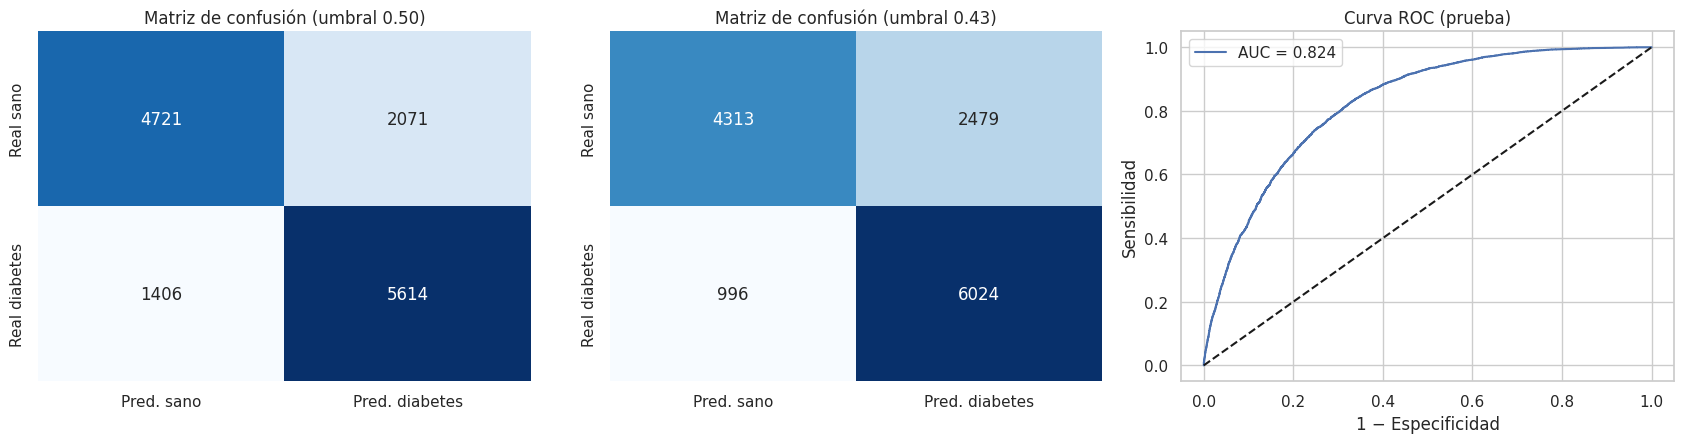

                      precision    recall  f1-score   support

        Sin diabetes      0.812     0.635     0.713      6792
Diabetes/prediabetes      0.708     0.858     0.776      7020

            accuracy                          0.748     13812
           macro avg      0.760     0.747     0.744     13812
        weighted avg      0.760     0.748     0.745     13812



In [ ]:
proba_test = pipe_final.predict_proba(X_test)[:, 1]
m05 = metricas(y_test, proba_test, 0.5)
mum = metricas(y_test, proba_test, UMBRAL)

comparacion_umbral = pd.DataFrame({"Umbral 0.50": m05, f"Umbral {UMBRAL:.2f}": mum}).T
display(comparacion_umbral[["Accuracy", "Precision", "Recall", "Especificidad", "F1", "F2", "ROC_AUC", "FN", "FP"]].round(4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, (t, m) in zip(ax[:2], [(0.5, m05), (UMBRAL, mum)]):
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Pred. sano", "Pred. diabetes"], yticklabels=["Real sano", "Real diabetes"])
    a.set_title(f"Matriz de confusión (umbral {t:.2f})")
fpr, tpr, _ = roc_curve(y_test, proba_test)
ax[2].plot(fpr, tpr, label=f"AUC = {m05['ROC_AUC']:.3f}"); ax[2].plot([0, 1], [0, 1], "k--")
ax[2].set_xlabel("1 − Especificidad"); ax[2].set_ylabel("Sensibilidad"); ax[2].set_title("Curva ROC (prueba)"); ax[2].legend()
plt.tight_layout(); plt.show()

print(classification_report(y_test, (proba_test >= UMBRAL).astype(int), target_names=["Sin diabetes", "Diabetes/prediabetes"], digits=3))

In [ ]:
PREVALENCIA_REAL = 0.139   # ≈ 35 346 positivos de 253 680 registros en el archivo sin balancear de la misma fuente (verificar)
sens, esp = mum["Recall"], mum["Especificidad"]
vpp_real = sens * PREVALENCIA_REAL / (sens * PREVALENCIA_REAL + (1 - esp) * (1 - PREVALENCIA_REAL))

display(Markdown(f"""
**Interpretación técnica de las métricas (umbral {UMBRAL:.2f}).**
- **Sensibilidad (Recall) = {sens:.3f}:** de {m05['TP']+m05['FN']:,} personas con diabetes/prediabetes en prueba, el modelo detecta {mum['TP']:,} y deja pasar **{mum['FN']:,}** (falsos negativos);
  con el umbral 0.50 serían {m05['FN']:,}. Reducir {m05['FN']-mum['FN']:,} falsos negativos costó **{mum['FP']-m05['FP']:,} falsos positivos adicionales** (especificidad {m05['Especificidad']:.3f} → {esp:.3f}).
- **Precisión = {mum['Precision']:.3f}:** de cada 100 alertas, ~{mum['Precision']*100:.0f} corresponden a personas realmente positivas **en este conjunto balanceado**.
- **Accuracy = {mum['Accuracy']:.3f}** (vs {m05['Accuracy']:.3f} con 0.50): {"prácticamente no cambia" if abs(mum['Accuracy']-m05['Accuracy'])<0.005 else "cambia"} al mover el umbral; lo que sí cambia es **qué tipo de error se comete**: el Accuracy no lo muestra, por eso no basta como criterio.
- **ROC-AUC = {m05['ROC_AUC']:.3f}:** si se eligen al azar un paciente positivo y uno negativo, el modelo asigna mayor riesgo al positivo en ~{m05['ROC_AUC']*100:.0f} % de los casos.
- **Limitación clave:** el archivo está **balanceado artificialmente** (50 % positivos). En una población con prevalencia ≈ {PREVALENCIA_REAL:.1%}, con esta sensibilidad y especificidad el valor predictivo positivo bajaría a ~**{vpp_real:.0%}**.
  Por eso la probabilidad que devuelve la app **no es el riesgo real** de la persona, sino una puntuación relativa en una muestra balanceada.
"""))


**Interpretación técnica de las métricas (umbral 0.43).**
- **Sensibilidad (Recall) = 0.858:** de 7,020 personas con diabetes/prediabetes en prueba, el modelo detecta 6,024 y deja pasar **996** (falsos negativos);
  con el umbral 0.50 serían 1,406. Reducir 410 falsos negativos costó **408 falsos positivos adicionales** (especificidad 0.695 → 0.635).
- **Precisión = 0.708:** de cada 100 alertas, ~71 corresponden a personas realmente positivas **en este conjunto balanceado**.
- **Accuracy = 0.748** (vs 0.748 con 0.50): prácticamente no cambia al mover el umbral; lo que sí cambia es **qué tipo de error se comete**: el Accuracy no lo muestra, por eso no basta como criterio.
- **ROC-AUC = 0.824:** si se eligen al azar un paciente positivo y uno negativo, el modelo asigna mayor riesgo al positivo en ~82 % de los casos.
- **Limitación clave:** el archivo está **balanceado artificialmente** (50 % positivos). En una población con prevalencia ≈ 13.9%, con esta sensibilidad y especificidad el valor predictivo positivo bajaría a ~**28%**.
  Por eso la probabilidad que devuelve la app **no es el riesgo real** de la persona, sino una puntuación relativa en una muestra balanceada.


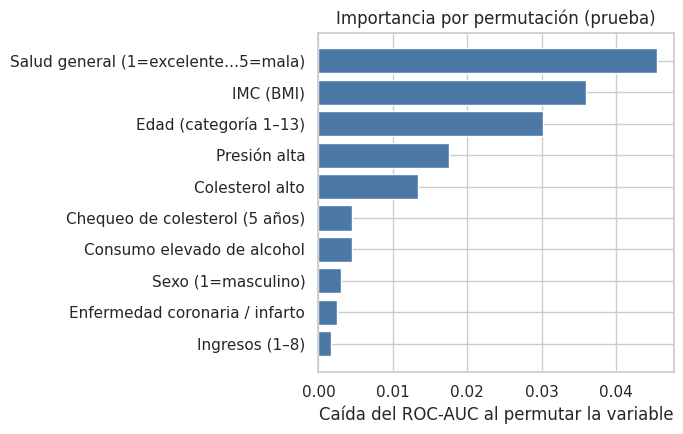

**Interpretación.** Las variables que más deterioran el ROC-AUC al desordenarse son: `genhlth` (0.046), `bmi` (0.036), `age` (0.030), `highbp` (0.018), `highchol` (0.013). La importancia por permutación mide el efecto sobre el rendimiento y no es causal.

In [ ]:
from sklearn.inspection import permutation_importance
muestra = X_test.sample(min(3000, len(X_test)), random_state=RANDOM_STATE)
pi = permutation_importance(pipe_final, muestra, y_test.loc[muestra.index], scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
imp_top = imp.head(10)

plt.figure(figsize=(7, 4.5))
plt.barh([ETIQUETAS[c] for c in imp_top.index][::-1], imp_top.values[::-1], color="#4C78A8")
plt.xlabel("Caída del ROC-AUC al permutar la variable"); plt.title("Importancia por permutación (prueba)"); plt.tight_layout(); plt.show()
display(Markdown("**Interpretación.** Las variables que más deterioran el ROC-AUC al desordenarse son: " +
                 ", ".join(f"`{c}` ({v:.3f})" for c, v in imp_top.head(5).items()) +
                 ". La importancia por permutación mide el efecto sobre el rendimiento y no es causal."))

## 9. Agrupamiento K-Means (análisis complementario, no se despliega)
Se **calculan** la inercia y el coeficiente de silueta para k = 2…6 (en el corte 2 se afirmó haberlos usado, pero no estaban en el notebook) y se justifica k = 3.

,k,inercia,silueta
0,2,1.279928e+06,0.1606
1,3,1.210603e+06,0.0741
2,4,1.145457e+06,0.0819
3,5,1.107578e+06,0.0725
4,6,1.050003e+06,0.0807


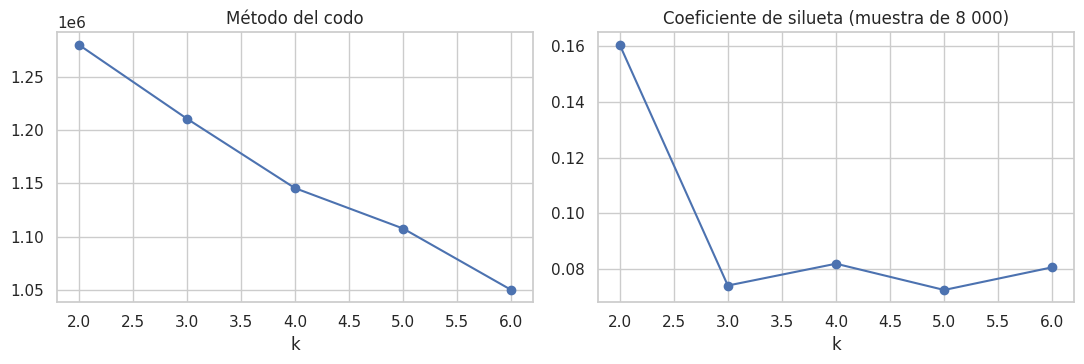

,n,prevalencia_diabetes,highbp,highchol,bmi,genhlth,diffwalk,physactivity,income,% de la muestra
Perfil 1 (mayor prevalencia),16370,0.758,0.773,0.697,33.160,4.070,0.801,0.420,3.901,0.237
Perfil 2 (intermedia),28098,0.630,0.877,0.691,30.328,2.787,0.139,0.730,5.873,0.407
Perfil 3 (menor prevalencia),24589,0.203,0.088,0.238,27.398,2.148,0.034,0.842,6.564,0.356



**Interpretación.** La silueta es **baja** en todos los k (máximo 0.16 en k = 2; con k = 3: 0.07):
no hay grupos naturalmente separados, sino un continuo de riesgo. Se usa k = 3 por **interpretabilidad** (riesgo alto / intermedio / bajo), no porque la estructura sea nítida.
La prevalencia de diabetes pasa de 20.3% a 75.8% entre el perfil de menor y mayor riesgo, sin haber usado la etiqueta para formar los grupos.
Los perfiles se nombran por su prevalencia para que la tabla del informe coincida exactamente con esta salida.


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Xs = StandardScaler().fit_transform(X)
idx_sil = np.random.RandomState(RANDOM_STATE).choice(len(Xs), size=min(8000, len(Xs)), replace=False)
res_k = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5).fit(Xs)
    res_k.append({"k": k, "inercia": km.inertia_, "silueta": silhouette_score(Xs[idx_sil], km.labels_[idx_sil])})
res_k = pd.DataFrame(res_k); display(res_k.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(res_k.k, res_k.inercia, "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k")
ax[1].plot(res_k.k, res_k.silueta, "o-"); ax[1].set_title("Coeficiente de silueta (muestra de 8 000)"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

km3 = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(Xs)
d_cl = X.assign(cluster=km3.labels_, diabetes_binary=y.values)
perfil = d_cl.groupby("cluster").agg(n=("bmi", "size"), prevalencia_diabetes=("diabetes_binary", "mean"), highbp=("highbp", "mean"),
                                     highchol=("highchol", "mean"), bmi=("bmi", "mean"), genhlth=("genhlth", "mean"),
                                     diffwalk=("diffwalk", "mean"), physactivity=("physactivity", "mean"), income=("income", "mean"))
perfil["% de la muestra"] = perfil.n / perfil.n.sum()
perfil = perfil.sort_values("prevalencia_diabetes", ascending=False)
perfil.index = [f"Perfil {i+1} ({n})" for i, n in enumerate(["mayor prevalencia", "intermedia", "menor prevalencia"])]
display(perfil.round(3))

mejor_sil = res_k.loc[res_k.silueta.idxmax()]
display(Markdown(f"""
**Interpretación.** La silueta es **baja** en todos los k (máximo {mejor_sil.silueta:.2f} en k = {int(mejor_sil.k)}; con k = 3: {res_k.set_index('k').loc[3,'silueta']:.2f}):
no hay grupos naturalmente separados, sino un continuo de riesgo. Se usa k = 3 por **interpretabilidad** (riesgo alto / intermedio / bajo), no porque la estructura sea nítida.
La prevalencia de diabetes pasa de {perfil.iloc[2]['prevalencia_diabetes']:.1%} a {perfil.iloc[0]['prevalencia_diabetes']:.1%} entre el perfil de menor y mayor riesgo, sin haber usado la etiqueta para formar los grupos.
Los perfiles se nombran por su prevalencia para que la tabla del informe coincida exactamente con esta salida.
"""))

## 10. Serialización del pipeline completo con `joblib`
Se guarda **un solo objeto** que incluye el preprocesamiento (`StandardScaler`) y el modelo entrenado. La aplicación solo lo carga; nunca entrena.
Junto con él se guardan los metadatos (umbral, métricas, matriz de confusión, rangos de las variables) y tres registros de prueba para verificar la coincidencia notebook ↔ Streamlit.

In [ ]:
RUTA_MODELO = f"{CARPETA_ARTEFACTOS}/modelo_diabetes_pipeline.joblib"
joblib.dump(pipe_final, RUTA_MODELO, compress=3)

# Prueba de ida y vuelta
recargado = joblib.load(RUTA_MODELO)
assert np.allclose(recargado.predict_proba(X_test)[:, 1], proba_test), "El pipeline recargado no reproduce las probabilidades"
print("Ida y vuelta OK. Tamaño del archivo: %.2f MB" % (os.path.getsize(RUTA_MODELO) / 1e6))
print("Pasos del pipeline:", [n for n, _ in recargado.steps])

# Registros conocidos del conjunto de prueba: un positivo detectado, un negativo y un falso negativo (error real del modelo)
pred_um = (proba_test >= UMBRAL).astype(int)
yt = y_test.values
ix = {"verdadero_positivo": np.where((yt == 1) & (pred_um == 1))[0][0],
      "verdadero_negativo": np.where((yt == 0) & (pred_um == 0))[0][0],
      "falso_negativo": np.where((yt == 1) & (pred_um == 0))[0][0]}
registros = []
for nombre, i in ix.items():
    registros.append({"caso": nombre, "indice_original": int(X_test.index[i]), "entradas": {c: float(X_test.iloc[i][c]) for c in FEATURES},
                      "diabetes_real": int(yt[i]), "probabilidad_notebook": float(proba_test[i]), "prediccion_notebook": int(pred_um[i])})
with open(f"{CARPETA_ARTEFACTOS}/registros_conocidos.json", "w", encoding="utf-8") as f:
    json.dump(registros, f, ensure_ascii=False, indent=2)
display(pd.DataFrame([{k: r[k] for k in ("caso", "indice_original", "diabetes_real", "probabilidad_notebook", "prediccion_notebook")} for r in registros]).round(6))

Ida y vuelta OK. Tamaño del archivo: 0.22 MB
Pasos del pipeline: ['prep', 'clf']


,caso,indice_original,diabetes_real,probabilidad_notebook,prediccion_notebook
0,verdadero_positivo,48151,1,0.719744,1
1,verdadero_negativo,19201,0,0.333070,0
2,falso_negativo,56380,1,0.419943,0


In [ ]:
def _py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, pd.Series): return o.to_dict()
    return str(o)

paso = max(1, len(fpr) // 120)
metadata = {
    "modelo": NOMBRE_FINAL, "hiperparametros": mejores_params, "umbral": UMBRAL, "recall_objetivo": RECALL_OBJETIVO,
    "prevalencia_real_supuesta": PREVALENCIA_REAL, "vpp_poblacion_real": vpp_real,
    "random_state": RANDOM_STATE, "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "features": FEATURES, "rangos": {c: [float(X[c].min()), float(X[c].max())] for c in FEATURES},
    "metricas_test_umbral_05": m05, "metricas_test_umbral_elegido": mum,
    "cv_antes": tabla_antes.to_dict(orient="records"), "cv_despues": tabla_despues.to_dict(orient="records"),
    "roc": {"fpr": fpr[::paso], "tpr": tpr[::paso], "auc": m05["ROC_AUC"]},
    "importancia_permutacion": imp_top.rename(index=ETIQUETAS).to_dict(), "curva_umbral": curva.to_dict(orient="list"),
    "limpieza": resumen_limpieza.to_dict(orient="records"),
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                  "numpy": np.__version__, "joblib": joblib.__version__},
}
with open(f"{CARPETA_ARTEFACTOS}/metadata_modelo.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=_py)

# requirements.txt con las versiones EXACTAS con las que se creó el .joblib
reqs = {"streamlit": None, "plotly": None, "pandas": pd.__version__, "numpy": np.__version__,
        "scikit-learn": sklearn.__version__, "joblib": joblib.__version__}
try:
    import streamlit; reqs["streamlit"] = streamlit.__version__
except ImportError:
    reqs["streamlit"] = "1.66.1"        # ajustar a la versión instalada en el entorno donde se pruebe la app
try:
    import plotly; reqs["plotly"] = plotly.__version__
except ImportError:
    reqs["plotly"] = "6.0.1"
with open("requirements.txt", "w") as f:
    f.write("\n".join(f"{k}=={v}" for k, v in reqs.items()) + "\n")
print(open("requirements.txt").read())
print("Archivos en", CARPETA_ARTEFACTOS, ":", sorted(os.listdir(CARPETA_ARTEFACTOS)))

streamlit==1.66.1
plotly==7.1.0
pandas==3.0.2
numpy==2.4.4
scikit-learn==1.8.0
joblib==1.5.3

Archivos en artefactos : ['eda_muestra.csv', 'eda_stats.json', 'metadata_modelo.json', 'modelo_diabetes_pipeline.joblib', 'registros_conocidos.json']


## 11. Conclusiones (generadas con las cifras de este mismo notebook)

In [ ]:
display(Markdown(f"""
1. **Datos.** {n_filas_ini:,} registros → {len(df):,} tras eliminar {n_dup:,} duplicados; sin nulos; clases {conteo[0]:,} / {conteo[1]:,}.
2. **Modelo final.** {NOMBRE_FINAL} dentro de un `Pipeline` con estandarización. ROC-AUC en validación cruzada: {mejor_cv['CV_roc_auc']:.4f} ± {mejor_cv['CVstd_roc_auc']:.4f}
   (Gradient Boosting del corte 2: {gb_antes['CV_roc_auc']:.4f}). En prueba: ROC-AUC {m05['ROC_AUC']:.3f} (brecha de sobreajuste {fila_final['AUC_train']-fila_final['Test_ROC_AUC']:.3f}). La optimización de hiperparámetros no cambió el ROC-AUC de forma apreciable; la ganancia de sensibilidad viene del umbral.
3. **Decisión clínica.** Umbral {UMBRAL:.2f} elegido sin tocar la prueba, con meta de sensibilidad ≥ {RECALL_OBJETIVO:.0%}. En prueba: Recall {mum['Recall']:.3f}, especificidad {mum['Especificidad']:.3f},
   falsos negativos {mum['FN']:,} (con 0.50 eran {m05['FN']:,}), falsos positivos {mum['FP']:,}.
4. **Variables más influyentes (permutación):** {", ".join(f"`{c}`" for c in imp_top.head(5).index)}.
5. **K-Means.** Silueta baja ({res_k.set_index('k').loc[3,'silueta']:.2f} con k = 3): los perfiles describen un gradiente de riesgo, no grupos separados.
6. **Limitaciones.** (i) Dataset balanceado artificialmente: las probabilidades no equivalen a riesgo poblacional (VPP estimado ≈ {vpp_real:.0%} con prevalencia {PREVALENCIA_REAL:.1%}).
   (ii) Datos autorreportados de una encuesta de EE. UU. de 2015: sin validación externa ni en población colombiana. (iii) La variable objetivo mezcla diabetes y prediabetes.
   (iv) Modelo de apoyo académico: **no sustituye** una decisión médica.
"""))


1. **Datos.** 70,692 registros → 69,057 tras eliminar 1,635 duplicados; sin nulos; clases 33,960 / 35,097.
2. **Modelo final.** HistGradientBoosting (optimizado) dentro de un `Pipeline` con estandarización. ROC-AUC en validación cruzada: 0.8259 ± 0.0042
   (Gradient Boosting del corte 2: 0.8259). En prueba: ROC-AUC 0.824 (brecha de sobreajuste 0.010). La optimización de hiperparámetros no cambió el ROC-AUC de forma apreciable; la ganancia de sensibilidad viene del umbral.
3. **Decisión clínica.** Umbral 0.43 elegido sin tocar la prueba, con meta de sensibilidad ≥ 85%. En prueba: Recall 0.858, especificidad 0.635,
   falsos negativos 996 (con 0.50 eran 1,406), falsos positivos 2,479.
4. **Variables más influyentes (permutación):** `genhlth`, `bmi`, `age`, `highbp`, `highchol`.
5. **K-Means.** Silueta baja (0.07 con k = 3): los perfiles describen un gradiente de riesgo, no grupos separados.
6. **Limitaciones.** (i) Dataset balanceado artificialmente: las probabilidades no equivalen a riesgo poblacional (VPP estimado ≈ 28% con prevalencia 13.9%).
   (ii) Datos autorreportados de una encuesta de EE. UU. de 2015: sin validación externa ni en población colombiana. (iii) La variable objetivo mezcla diabetes y prediabetes.
   (iv) Modelo de apoyo académico: **no sustituye** una decisión médica.


## 12. Declaración y evaluación del uso de Inteligencia Artificial
> **El equipo debe revisar y ajustar este texto para que describa fielmente lo que hizo; el mismo contenido va en el `README.md`.**

* **Herramientas:** Gemini (borradores del informe y del código del corte 2) y Claude (auditoría del notebook del corte 2, reescritura del notebook, `app.py` y documentación del tercer corte).
* **Propósito:** revisar el pipeline, corregir errores de reproducibilidad, optimizar el modelo, construir la app en Streamlit y redactar documentación.
* **Prompt principal (tercer corte):** solicitud a Claude, con el PDF de la actividad, el informe y el notebook del corte 2 adjuntos, de actuar como profesor de Minería de Datos para auditar errores, optimizar el modelo con validación cruzada, serializarlo con `joblib` y construir `app.py`, `requirements.txt` y `README.md`.
* **Cómo se verificó:** se re-ejecutó el notebook completo de arriba hacia abajo; se reprodujeron las métricas del corte 2 con el CSV original; se comprobó la ida y vuelta del `joblib`; se compararon las predicciones de Streamlit con las del notebook sobre registros del conjunto de prueba (`tests/test_app.py`).
* **Problemas encontrados en las respuestas de la IA:** celdas con orden de ejecución mezclado y salidas obsoletas (columna `Cluster`); `drop_duplicates` solo impreso, no aplicado; sugerencia `df = df.drop_duplicates(inplace=True)` (deja `df = None`); *macro-recall* presentado como sensibilidad; escalado solo de `bmi`;
  afirmación de silueta de K-Means sin cálculo; cifras del informe del corte 2 (matriz de confusión y prevalencias de `highbp`/`highchol`) que no coincidían con el notebook ni con los datos.
* **Ajustes realizados:** los descritos en la sección "Qué cambió respecto al avance del segundo corte".